In [52]:
import os

os.listdir("Learning_set")


['Bearing2_1',
 'Bearing1_1',
 'Bearing3_2',
 'Bearing2_2',
 'Bearing1_2',
 'Bearing3_1']

In [53]:
sorted(os.listdir("Learning_set/Bearing1_1"))[:10]


['acc_00001.csv',
 'acc_00002.csv',
 'acc_00003.csv',
 'acc_00004.csv',
 'acc_00005.csv',
 'acc_00006.csv',
 'acc_00007.csv',
 'acc_00008.csv',
 'acc_00009.csv',
 'acc_00010.csv']

In [54]:
import pandas as pd

file_path = "Learning_set/Bearing1_1/acc_00001.csv"
df = pd.read_csv(file_path)

df.head()


,9,39,39.1,65664,0.552,-0.146
0,9,39,39,65703.0,0.501,-0.480
1,9,39,39,65742.0,0.138,0.435
2,9,39,39,65781.0,-0.423,0.240
3,9,39,39,65820.0,-0.802,0.020
4,9,39,39,65859.0,-0.364,0.112


In [55]:
import pandas as pd

file_path = "Learning_set/Bearing1_1/acc_00002.csv"
df = pd.read_csv(file_path)

df.head()

,9,39,49,65664,-0.14,-0.043
0,9,39,49,65703.0,-0.162,0.313
1,9,39,49,65742.0,-0.002,-0.388
2,9,39,49,65781.0,0.037,0.411
3,9,39,49,65820.0,-0.085,-0.292
4,9,39,49,65859.0,0.016,-0.431


In [56]:
df.columns = [
    "hour",
    "minute",
    "second",
    "sample_index",
    "sensor_1",
    "sensor_2"
]

df.head()


,hour,minute,second,sample_index,sensor_1,sensor_2
0,9,39,49,65703.0,-0.162,0.313
1,9,39,49,65742.0,-0.002,-0.388
2,9,39,49,65781.0,0.037,0.411
3,9,39,49,65820.0,-0.085,-0.292
4,9,39,49,65859.0,0.016,-0.431


[hour, minute, second, sample_index, sensor_1_acc, sensor_2_acc]


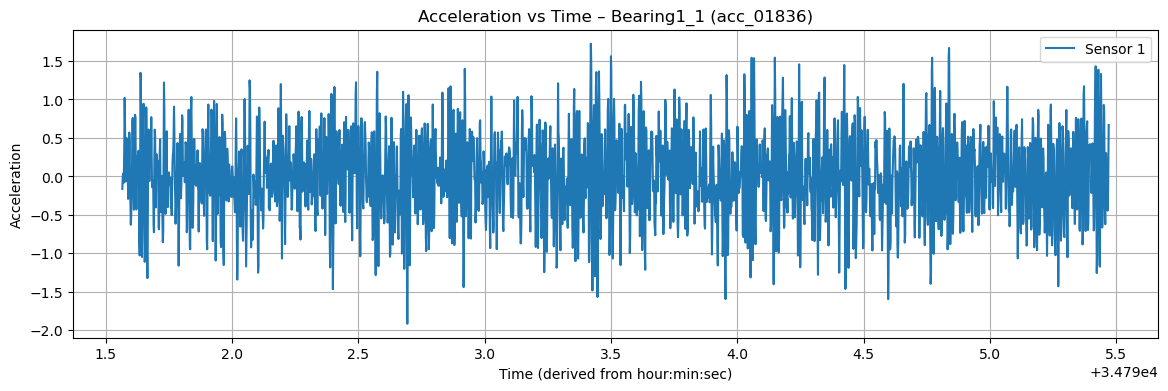

In [59]:
import numpy as np
import matplotlib.pyplot as plt

# create real time axis from dataset
fs = 25600  # sampling frequency

df['time_sec'] = (
    df['hour'] * 3600 +
    df['minute'] * 60 +
    df['second'] +
    df['sample_index'] / fs
)

plt.figure(figsize=(14,4))
plt.plot(df['time_sec'], df["sensor_1"], label="Sensor 1")

plt.xlabel("Time (derived from hour:min:sec)")
plt.ylabel("Acceleration")
plt.title("Acceleration vs Time – Bearing1_1 (acc_01836)")
plt.legend()
plt.grid(True)
plt.show()


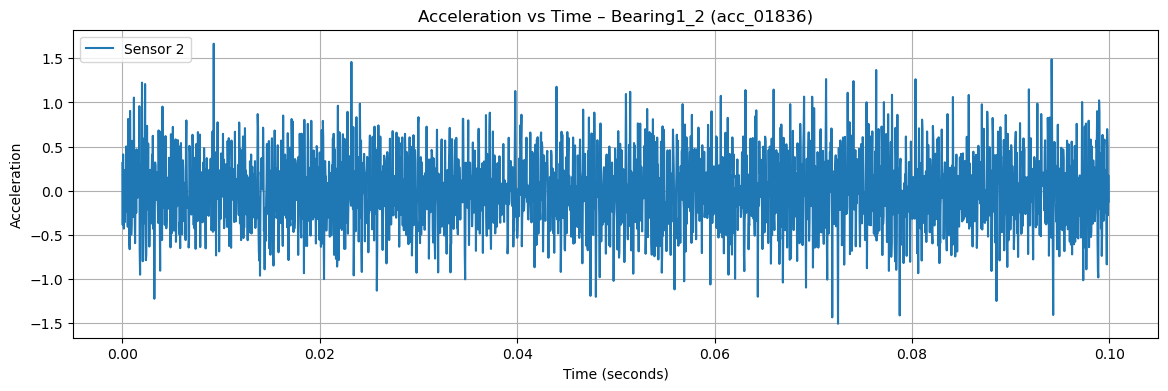

In [48]:
import numpy as np
import matplotlib.pyplot as plt

fs = 25600  

time = np.arange(len(df)) / fs

plt.figure(figsize=(14,4))
plt.plot(time, df["sensor_2"], label="Sensor 2")

plt.xlabel("Time (seconds)")
plt.ylabel("Acceleration")
plt.title("Acceleration vs Time – Bearing1_2 (acc_01836)")
plt.legend()
plt.grid(True)
plt.show()


In [78]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

bearing_folder = "Learning_set/Bearing1_1"
files = sorted(os.listdir(bearing_folder))

fs = 25600  


In [70]:
all_time = []
all_acc = []

fs = 25600
current_time = 0.0  

for file in files:
    if file.endswith(".csv"):
        df = pd.read_csv(
            os.path.join(bearing_folder, file),
            header=None,
            names=["hour","minute","second","sample_index","sensor_1","sensor_2"]
        )

        t = current_time + df["sample_index"] / fs

        all_time.append(t.values)
        all_acc.append(df["sensor_1"].values)

        current_time += 1.0


In [66]:
all_time = np.concatenate(all_time)
all_acc = np.concatenate(all_acc)


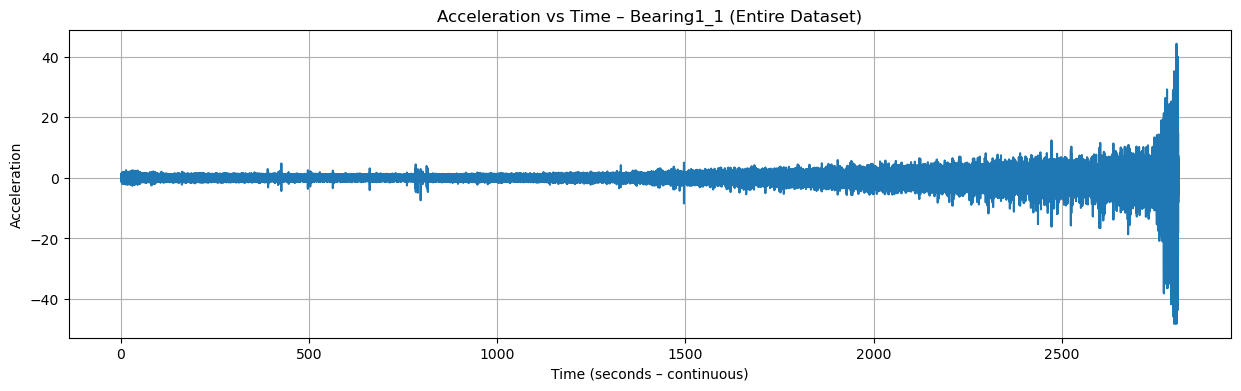

In [67]:
plt.figure(figsize=(15,4))
plt.plot(all_time, all_acc)

plt.xlabel("Time (seconds – continuous)")
plt.ylabel("Acceleration")
plt.title("Acceleration vs Time – Bearing1_1 (Entire Dataset)")
plt.grid(True)
plt.show()


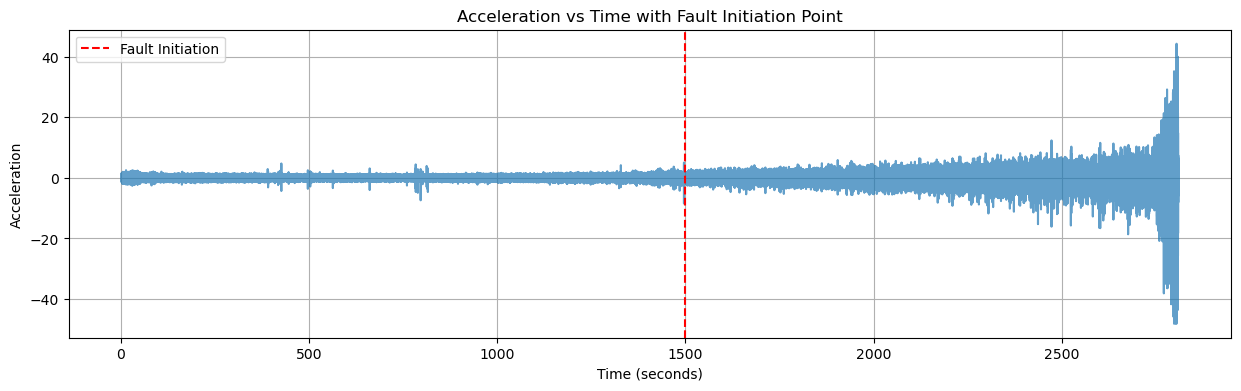

In [68]:
fault_time = 1500

plt.figure(figsize=(15,4))
plt.plot(all_time, all_acc, alpha=0.7)
plt.axvline(fault_time, color='red', linestyle='--', label='Fault Initiation')

plt.xlabel("Time (seconds)")
plt.ylabel("Acceleration")
plt.title("Acceleration vs Time with Fault Initiation Point")
plt.legend()
plt.grid(True)
plt.show()


In [79]:
all_time = []
all_acc = []

fs = 25600
current_time = 0.0  

for file in files:
    if file.endswith(".csv"):
        df = pd.read_csv(
            os.path.join(bearing_folder, file),
            header=None,
            names=["hour","minute","second","sample_index","sensor_1","sensor_2"]
        )

        t = current_time + df["sample_index"] / fs

        all_time.append(t.values)
        all_acc.append(df["sensor_2"].values)

        current_time += 1.0

In [80]:
all_time = np.concatenate(all_time)
all_acc = np.concatenate(all_acc)

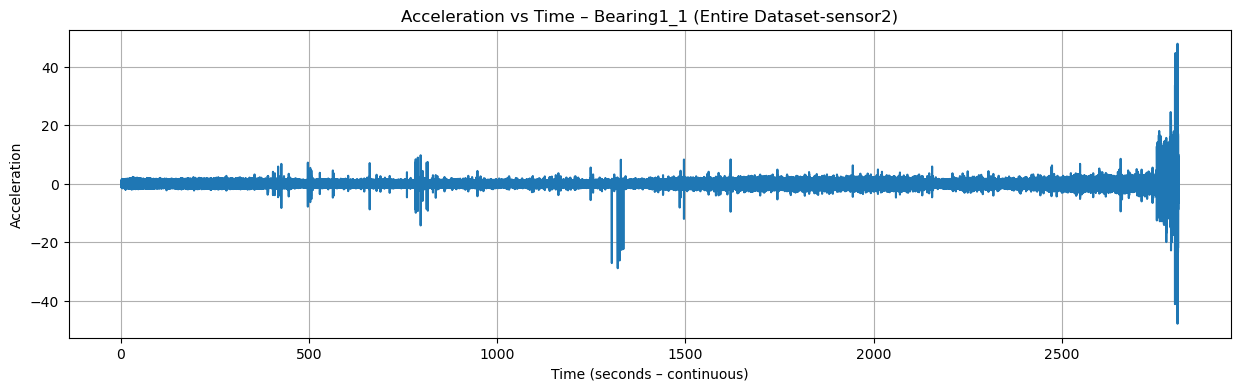

In [82]:
plt.figure(figsize=(15,4))
plt.plot(all_time, all_acc)

plt.xlabel("Time (seconds – continuous)")
plt.ylabel("Acceleration")
plt.title("Acceleration vs Time – Bearing1_1 (Entire Dataset-sensor2)")
plt.grid(True)
plt.show()

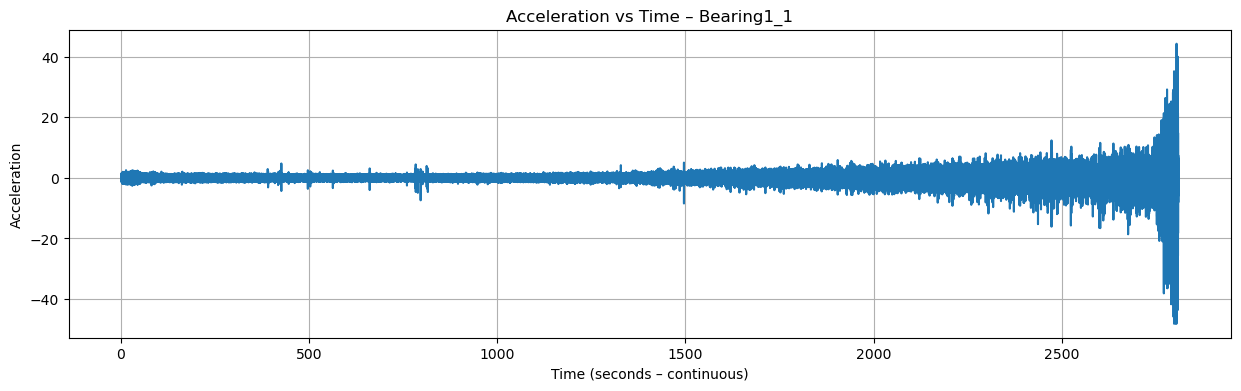

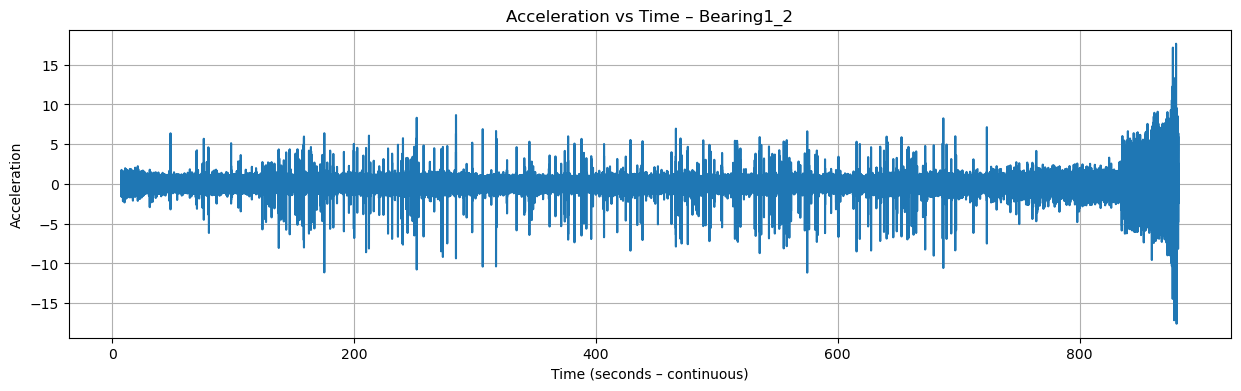

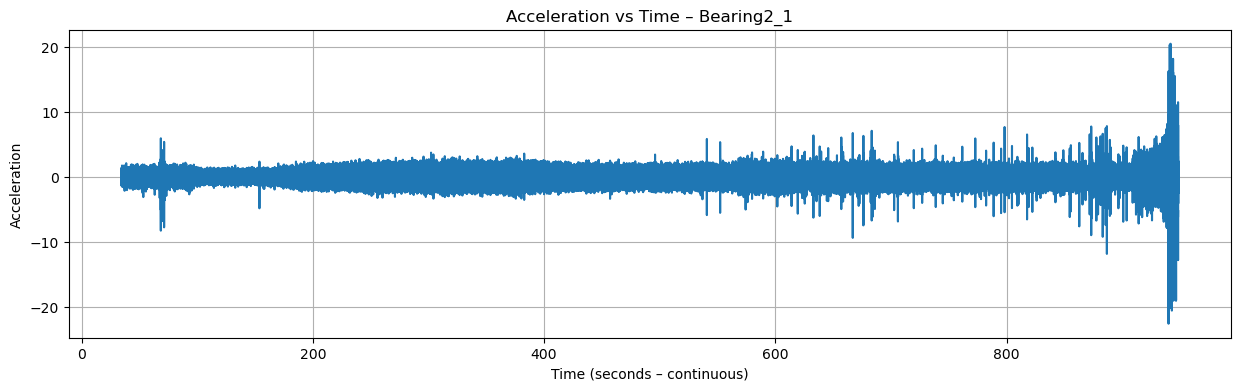

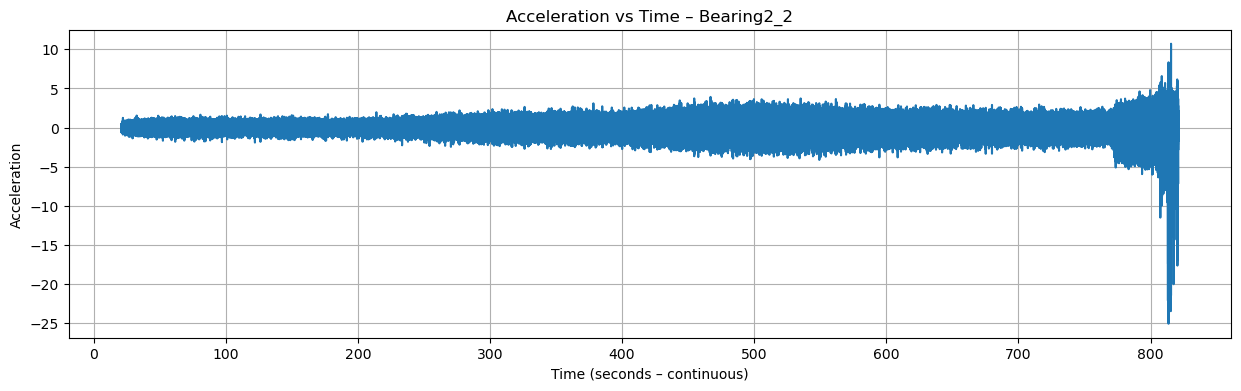

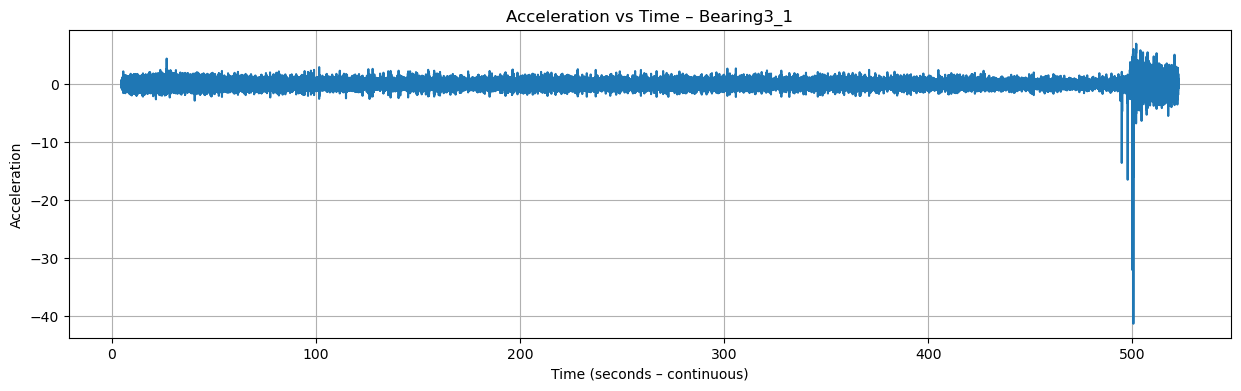

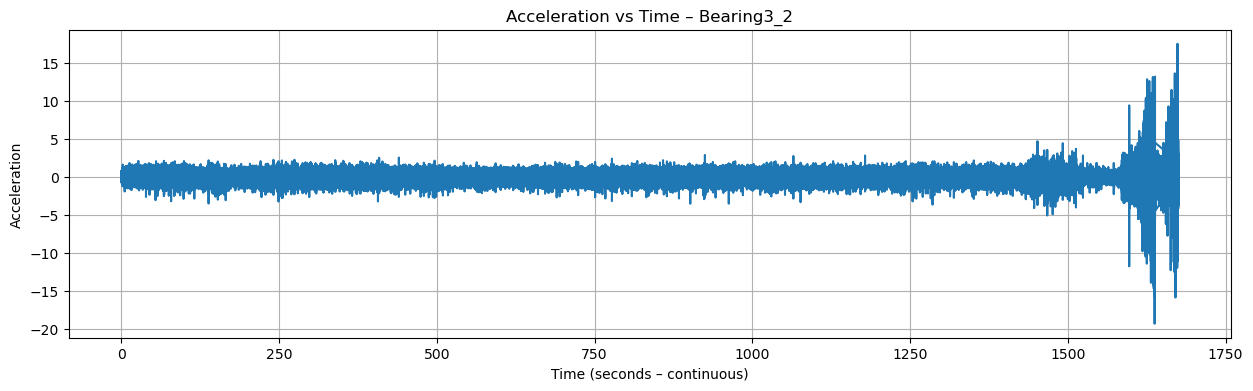

In [77]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE_DIR = "Learning_set"
fs = 25600 

def plot_bearing_acceleration(bearing_path, bearing_name):
    files = sorted(os.listdir(bearing_path))

    all_time = []
    all_acc = []

    current_time = 0.0  

    for file in files:
        if file.endswith(".csv"):
            df = pd.read_csv(
                os.path.join(bearing_path, file),
                header=None,
                names=["hour","minute","second","sample_index","sensor_1","sensor_2"]
            )

        
            t = current_time + df["sample_index"] / fs

            all_time.append(t.values)
            all_acc.append(df["sensor_1"].values)

            current_time += 1.0 

    all_time = np.concatenate(all_time)
    all_acc = np.concatenate(all_acc)

 
    plt.figure(figsize=(15,4))
    plt.plot(all_time, all_acc)
    plt.xlabel("Time (seconds – continuous)")
    plt.ylabel("Acceleration")
    plt.title(f"Acceleration vs Time – {bearing_name}")
    plt.grid(True)
    plt.show()


for bearing in sorted(os.listdir(BASE_DIR)):
    bearing_path = os.path.join(BASE_DIR, bearing)
    if os.path.isdir(bearing_path):
        plot_bearing_acceleration(bearing_path, bearing)


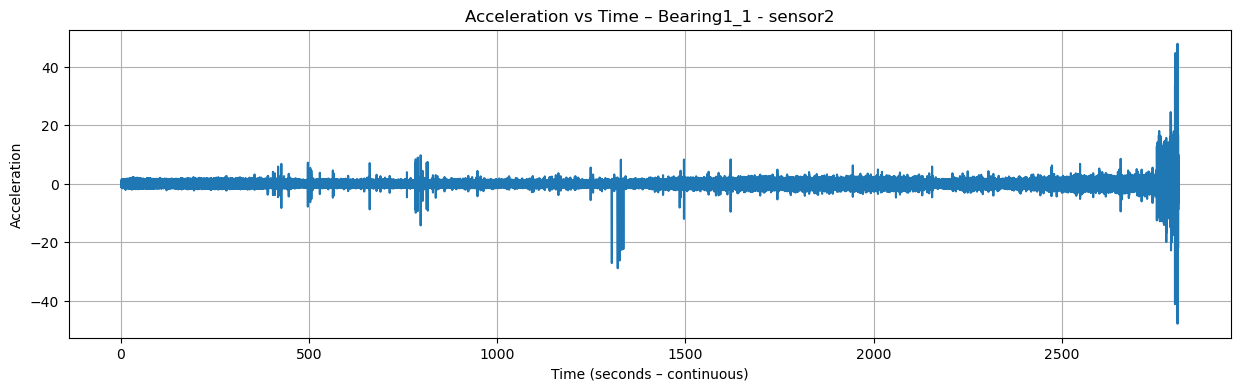

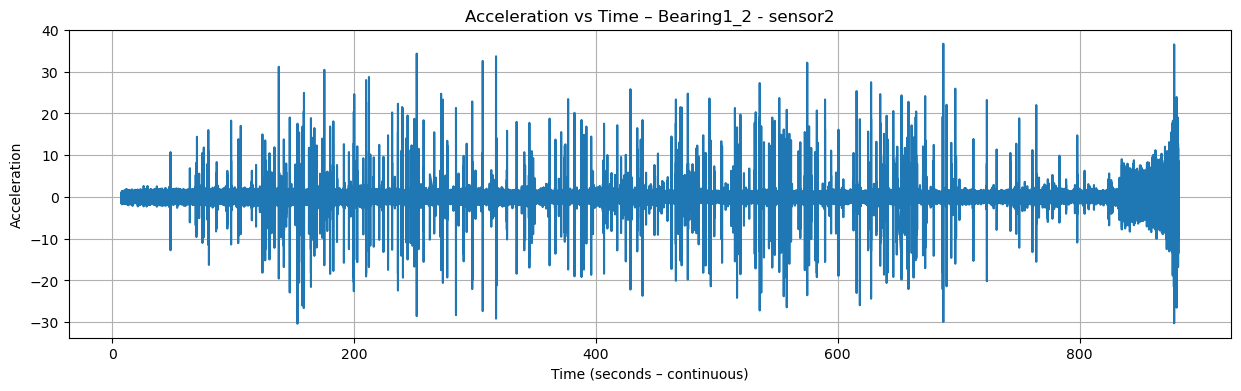

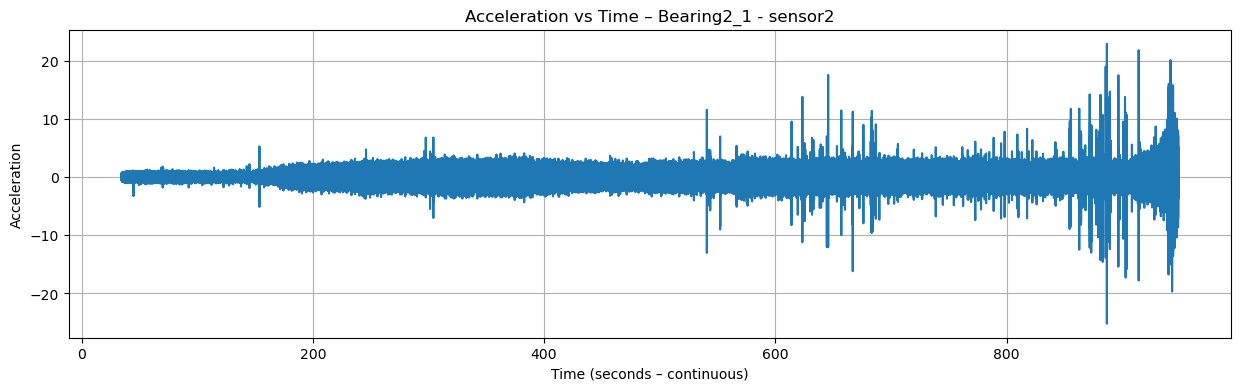

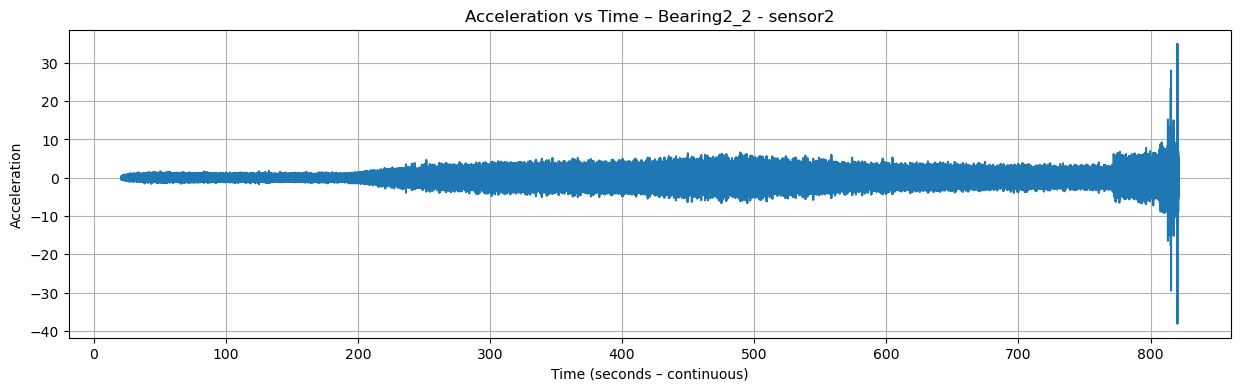

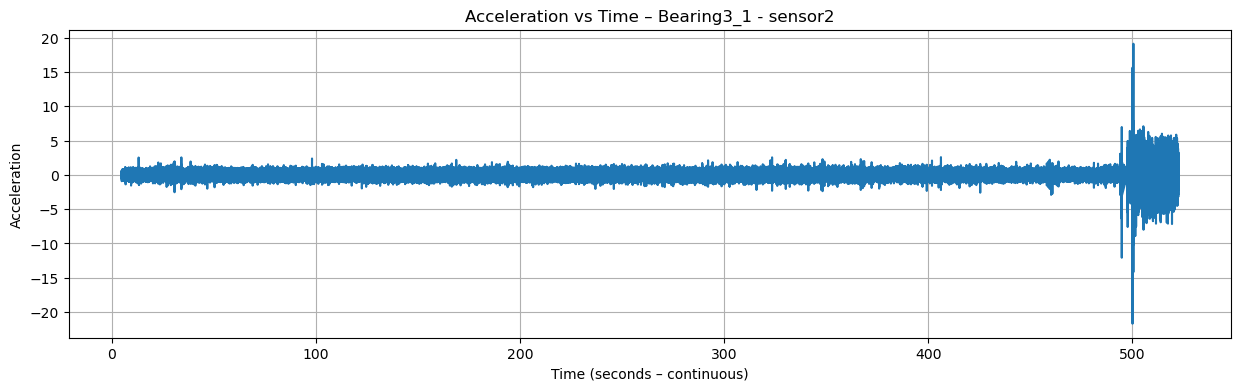

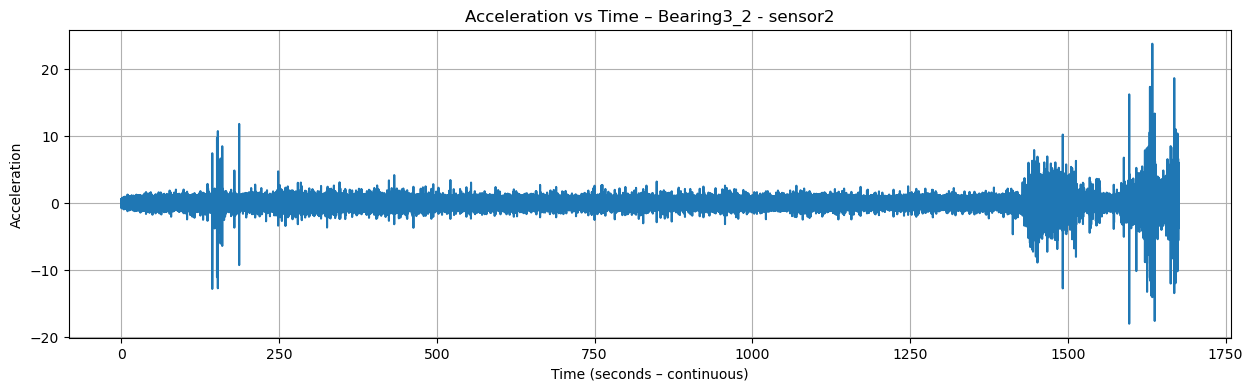

In [83]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE_DIR = "Learning_set"
fs = 25600 

def plot_bearing_acceleration(bearing_path, bearing_name):
    files = sorted(os.listdir(bearing_path))

    all_time = []
    all_acc = []

    current_time = 0.0  

    for file in files:
        if file.endswith(".csv"):
            df = pd.read_csv(
                os.path.join(bearing_path, file),
                header=None,
                names=["hour","minute","second","sample_index","sensor_1","sensor_2"]
            )

        
            t = current_time + df["sample_index"] / fs

            all_time.append(t.values)
            all_acc.append(df["sensor_2"].values)

            current_time += 1.0 

    all_time = np.concatenate(all_time)
    all_acc = np.concatenate(all_acc)

 
    plt.figure(figsize=(15,4))
    plt.plot(all_time, all_acc)
    plt.xlabel("Time (seconds – continuous)")
    plt.ylabel("Acceleration")
    plt.title(f"Acceleration vs Time – {bearing_name} - sensor2")
    plt.grid(True)
    plt.show()


for bearing in sorted(os.listdir(BASE_DIR)):
    bearing_path = os.path.join(BASE_DIR, bearing)
    if os.path.isdir(bearing_path):
        plot_bearing_acceleration(bearing_path, bearing)

In [49]:
import numpy as np

def mean_absolute_value(signal):
    return np.mean(np.abs(signal))


In [23]:
import os
import pandas as pd

bearing_folder = "Learning_set/Bearing1_1"
files = sorted(os.listdir(bearing_folder))
mav_sensor1 = []
mav_sensor2 = []

for file in files:
    if file.endswith(".csv"):
        df = pd.read_csv(os.path.join(bearing_folder, file), header=None)
        
        s1 = df.iloc[:, 4].values   # sensor 1
        s2 = df.iloc[:, 5].values   # sensor 2
        
        mav_sensor1.append(mean_absolute_value(s1))
        mav_sensor2.append(mean_absolute_value(s2))


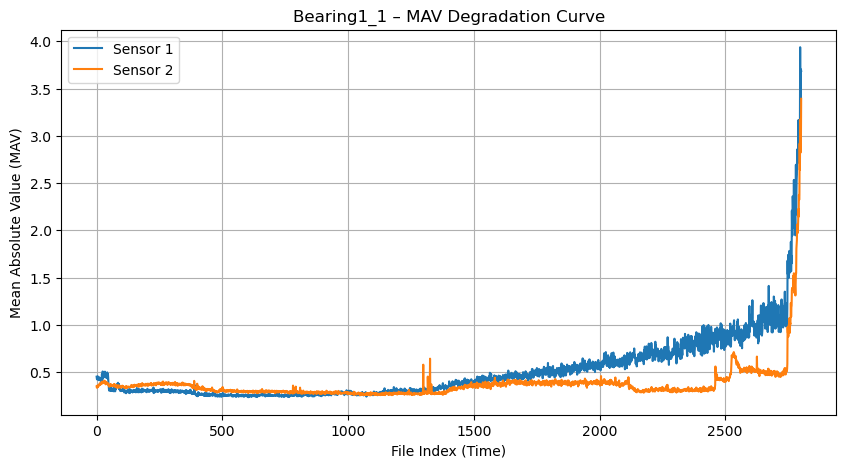

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
plt.plot(mav_sensor1, label="Sensor 1")
plt.plot(mav_sensor2, label="Sensor 2")

plt.xlabel("File Index (Time)")
plt.ylabel("Mean Absolute Value (MAV)")
plt.title("Bearing1_1 – MAV Degradation Curve")
plt.legend()
plt.grid(True)
plt.show()


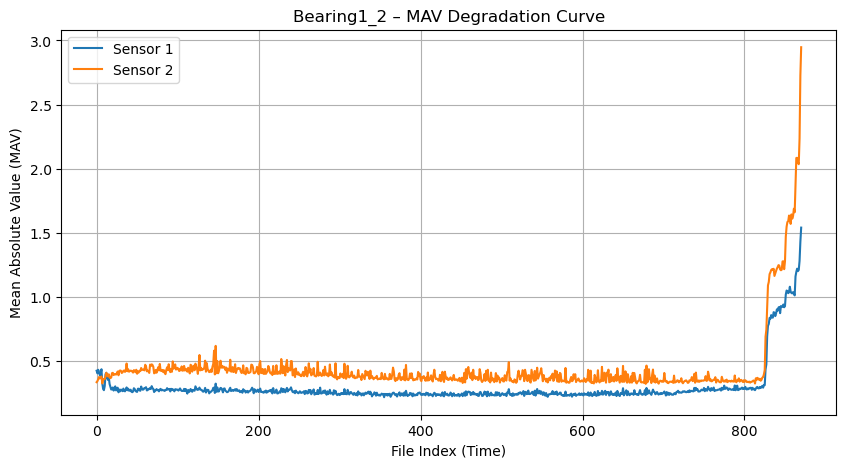

In [17]:
import os
import pandas as pd

bearing_folder = "Learning_set/Bearing1_2"
files = sorted(os.listdir(bearing_folder))

mav_sensor1 = []
mav_sensor2 = []

for file in files:
    if file.endswith(".csv"):
        df = pd.read_csv(os.path.join(bearing_folder, file), header=None)
        
        s1 = df.iloc[:, 4].values   
        s2 = df.iloc[:, 5].values   
        
        mav_sensor1.append(mean_absolute_value(s1))
        mav_sensor2.append(mean_absolute_value(s2))


plt.figure(figsize=(10,5))
plt.plot(mav_sensor1, label="Sensor 1")
plt.plot(mav_sensor2, label="Sensor 2")

plt.xlabel("File Index (Time)")
plt.ylabel("Mean Absolute Value (MAV)")
plt.title("Bearing1_2 – MAV Degradation Curve")
plt.legend()
plt.grid(True)
plt.show()

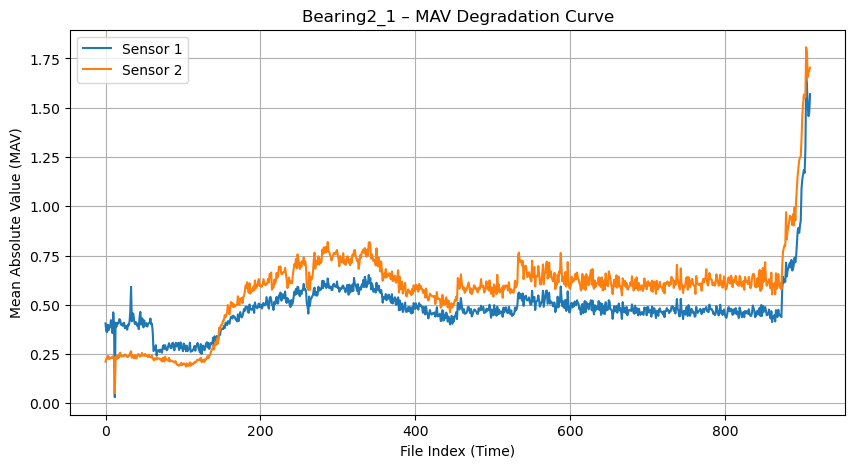

In [19]:
import os
import pandas as pd

bearing_folder = "Learning_set/Bearing2_1"
files = sorted(os.listdir(bearing_folder))

mav_sensor1 = []
mav_sensor2 = []

for file in files:
    if file.endswith(".csv"):
        df = pd.read_csv(os.path.join(bearing_folder, file), header=None)
        
        s1 = df.iloc[:, 4].values  
        s2 = df.iloc[:, 5].values  
        
        mav_sensor1.append(mean_absolute_value(s1))
        mav_sensor2.append(mean_absolute_value(s2))


plt.figure(figsize=(10,5))
plt.plot(mav_sensor1, label="Sensor 1")
plt.plot(mav_sensor2, label="Sensor 2")

plt.xlabel("File Index (Time)")
plt.ylabel("Mean Absolute Value (MAV)")
plt.title("Bearing2_1 – MAV Degradation Curve")
plt.legend()
plt.grid(True)
plt.show()

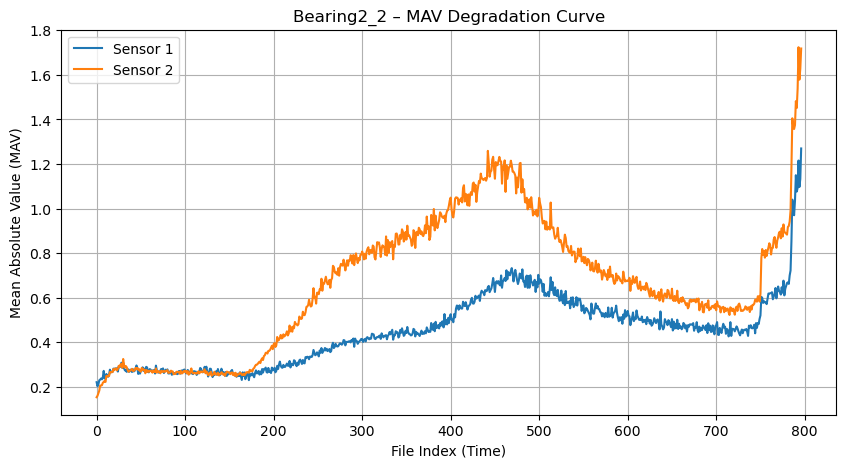

In [20]:
import os
import pandas as pd

bearing_folder = "Learning_set/Bearing2_2"
files = sorted(os.listdir(bearing_folder))

mav_sensor1 = []
mav_sensor2 = []

for file in files:
    if file.endswith(".csv"):
        df = pd.read_csv(os.path.join(bearing_folder, file), header=None)
        
        s1 = df.iloc[:, 4].values  
        s2 = df.iloc[:, 5].values   
        
        mav_sensor1.append(mean_absolute_value(s1))
        mav_sensor2.append(mean_absolute_value(s2))


plt.figure(figsize=(10,5))
plt.plot(mav_sensor1, label="Sensor 1")
plt.plot(mav_sensor2, label="Sensor 2")

plt.xlabel("File Index (Time)")
plt.ylabel("Mean Absolute Value (MAV)")
plt.title("Bearing2_2 – MAV Degradation Curve")
plt.legend()
plt.grid(True)
plt.show()

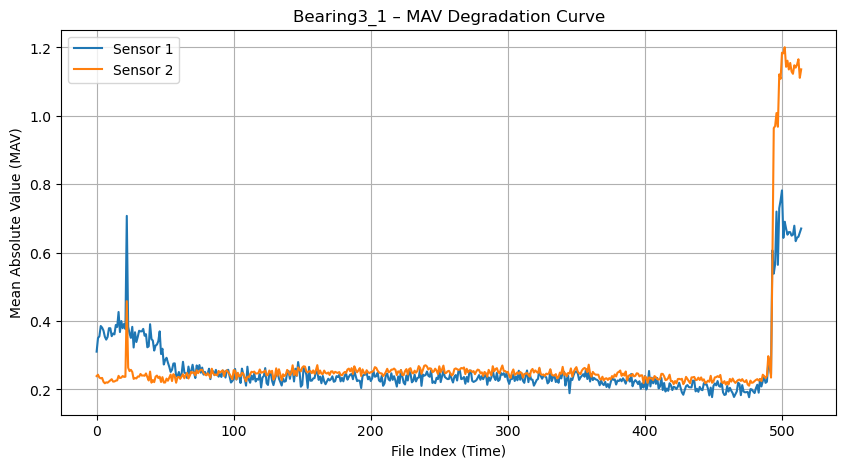

In [21]:
import os
import pandas as pd

bearing_folder = "Learning_set/Bearing3_1"
files = sorted(os.listdir(bearing_folder))

mav_sensor1 = []
mav_sensor2 = []

for file in files:
    if file.endswith(".csv"):
        df = pd.read_csv(os.path.join(bearing_folder, file), header=None)
        
        s1 = df.iloc[:, 4].values   # sensor 1
        s2 = df.iloc[:, 5].values   # sensor 2
        
        mav_sensor1.append(mean_absolute_value(s1))
        mav_sensor2.append(mean_absolute_value(s2))


plt.figure(figsize=(10,5))
plt.plot(mav_sensor1, label="Sensor 1")
plt.plot(mav_sensor2, label="Sensor 2")

plt.xlabel("File Index (Time)")
plt.ylabel("Mean Absolute Value (MAV)")
plt.title("Bearing3_1 – MAV Degradation Curve")
plt.legend()
plt.grid(True)
plt.show()

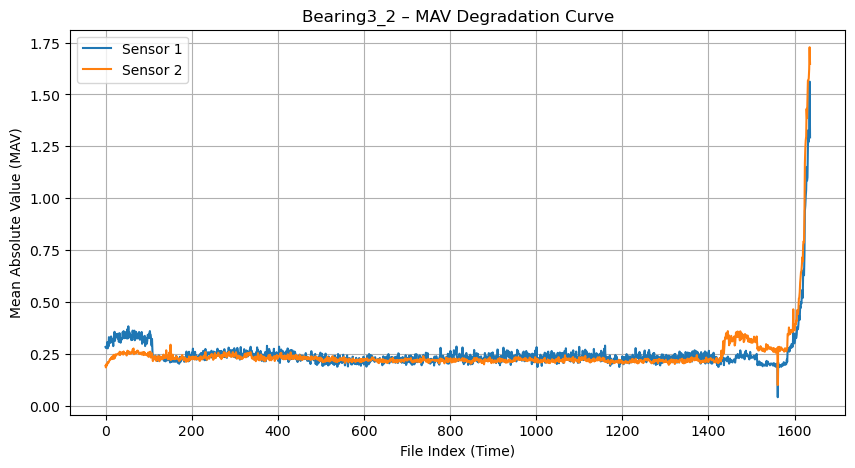

In [22]:
import os
import pandas as pd

bearing_folder = "Learning_set/Bearing3_2"
files = sorted(os.listdir(bearing_folder))

mav_sensor1 = []
mav_sensor2 = []

for file in files:
    if file.endswith(".csv"):
        df = pd.read_csv(os.path.join(bearing_folder, file), header=None)
        
        s1 = df.iloc[:, 4].values   # sensor 1
        s2 = df.iloc[:, 5].values   # sensor 2
        
        mav_sensor1.append(mean_absolute_value(s1))
        mav_sensor2.append(mean_absolute_value(s2))


plt.figure(figsize=(10,5))
plt.plot(mav_sensor1, label="Sensor 1")
plt.plot(mav_sensor2, label="Sensor 2")

plt.xlabel("File Index (Time)")
plt.ylabel("Mean Absolute Value (MAV)")
plt.title("Bearing3_2 – MAV Degradation Curve")
plt.legend()
plt.grid(True)
plt.show()